<a href="https://colab.research.google.com/github/ANJARRIZANDI/simuteh-2330511035/blob/main/notebook/B1_lingkungan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
%cd /content/simuteh-2330511035
!python src/buat_dataset_sintetis.py

/content/simuteh-2330511035
Selesai: 60 citra tersimpan di data/sintetis


In [13]:
%cd /content/simuteh-2330511035/notebook

/content/simuteh-2330511035/notebook


OpenCV 5.0.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 21 236
piksel (y=100, x=200) dalam urutan BGR: [156 189 204]


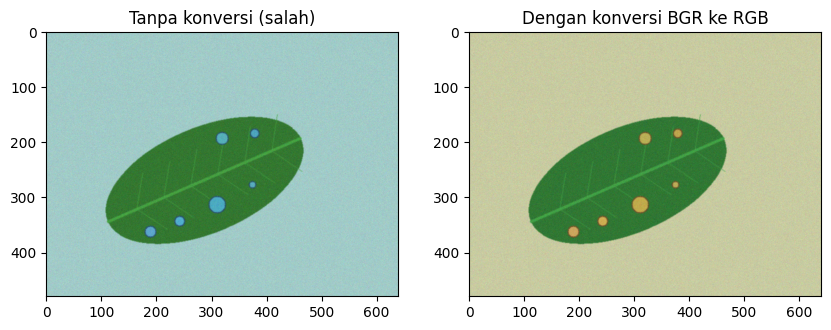

In [15]:
# Kode 1.1 Uji lingkungan dan struktur larik citra
import sys
sys.path.append("../src")
# agar utils_cv dapat diimpor dari notebook/
import cv2, numpy as np, skimage, matplotlib.pyplot as plt
from utils_cv import baca, tampil
print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
"| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])
# tampilkan citra TANPA dan DENGAN konversi BGR ke RGB
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB"); plt.savefig("../hasil/b1_bgr_rgb.png")

**P1:** Bagi petani, kelompok tani, dan petugas pengamat tanaman teh yang mengalami kesulitan dalam mengidentifikasi kondisi kesehatan daun teh secara cepat dan konsisten melalui pengamatan visual, kami membangun SIMUTEH (Sistem Identifikasi Mutu dan Kesehatan Daun Teh) yang menerima citra digital daun teh dan menghasilkan informasi klasifikasi kondisi daun berdasarkan tingkat kesehatan, yaitu sehat, terserang penyakit ringan, dan terserang penyakit berat. Dengan demikian, sistem ini diharapkan dapat membantu pengguna mengenali kondisi daun teh secara lebih cepat, mempermudah proses pemantauan tanaman, serta mendukung pengambilan keputusan dalam penanganan tanaman teh.





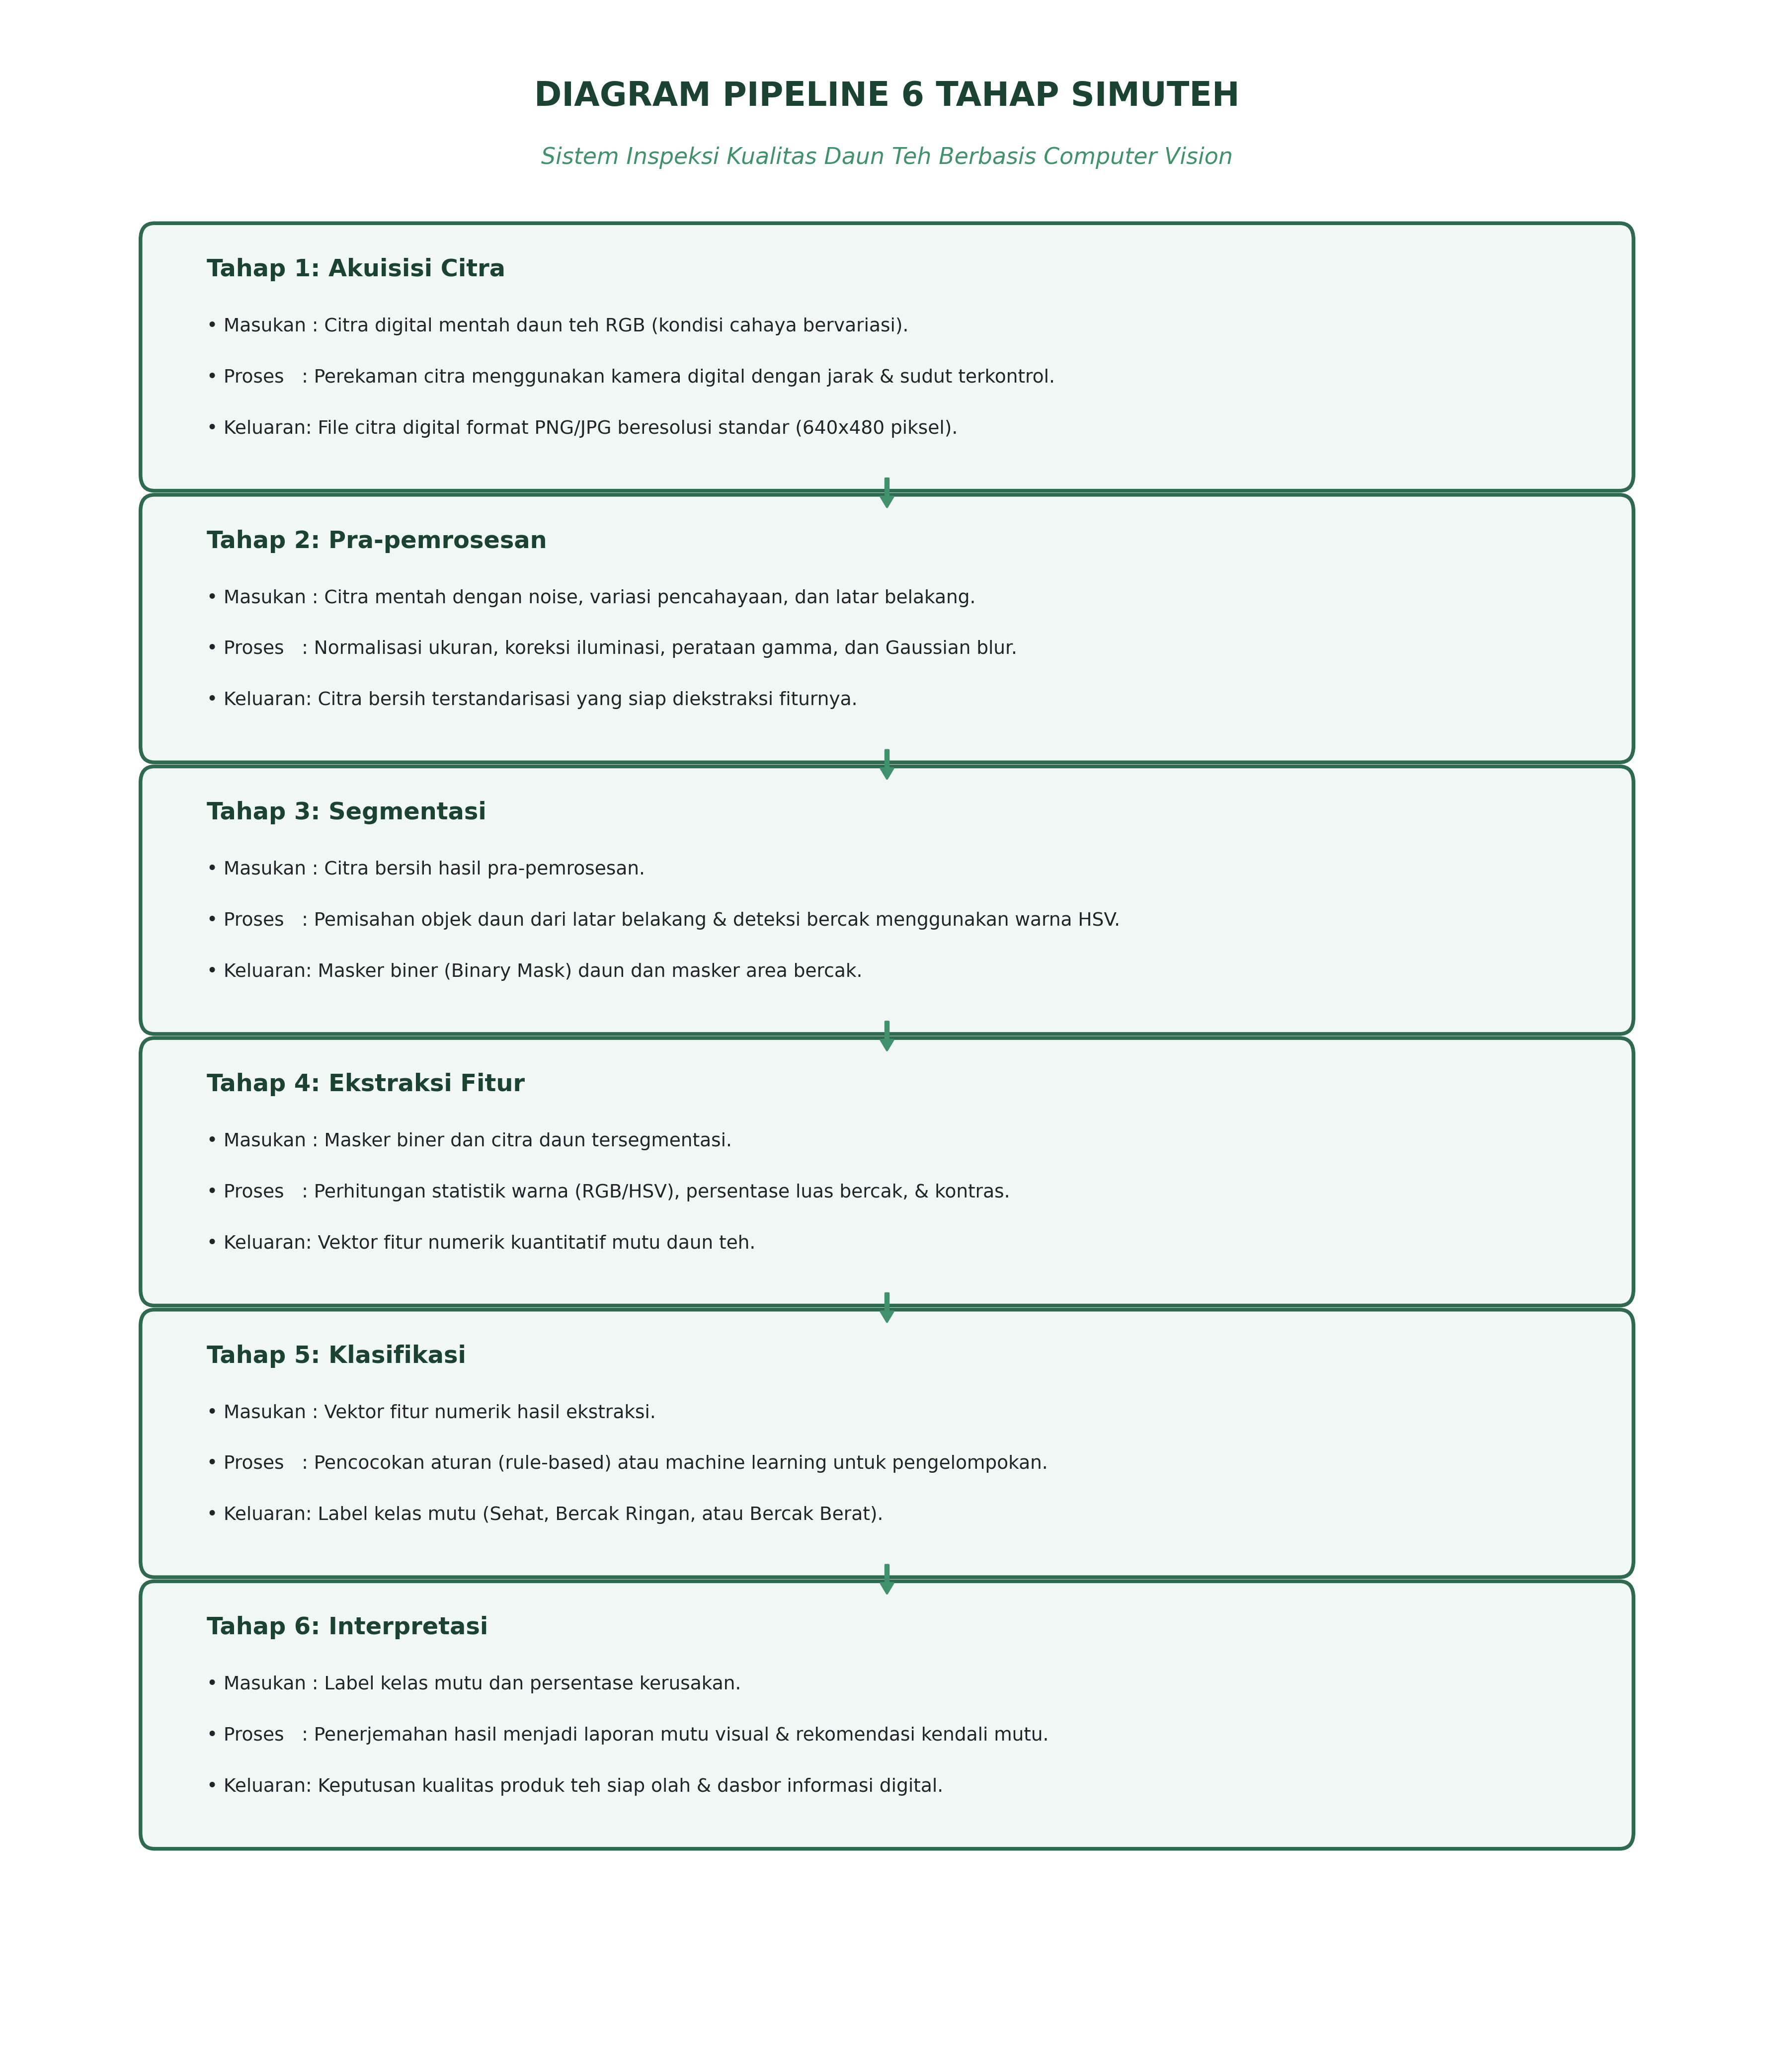

Diagram pipeline yang lebih rapi berhasil dibuat dan disimpan di ../hasil/b1_pipeline.png


In [16]:
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Pastikan folder hasil sudah tersedia
os.makedirs("../hasil", exist_ok=True)

# Membuat figur dengan kanvas yang proporsional dan bersih
fig, ax = plt.subplots(figsize=(12, 14), dpi=300)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

# Judul Utama Diagram
ax.text(50, 96, "DIAGRAM PIPELINE 6 TAHAP SIMUTEH",
        fontsize=16, fontweight='bold', ha='center', va='center', color='#1b4332')
ax.text(50, 93, "Sistem Inspeksi Kualitas Daun Teh Berbasis Computer Vision",
        fontsize=11, fontstyle='italic', ha='center', va='center', color='#40916c')

# Data 6 Tahapan SIMUTEH
tahapan = [
    {
        "no": "1", "judul": "Akuisisi Citra",
        "in": "Citra digital mentah daun teh RGB (kondisi cahaya bervariasi).",
        "proses": "Perekaman citra menggunakan kamera digital dengan jarak & sudut terkontrol.",
        "out": "File citra digital format PNG/JPG beresolusi standar (640x480 piksel)."
    },
    {
        "no": "2", "judul": "Pra-pemrosesan",
        "in": "Citra mentah dengan noise, variasi pencahayaan, dan latar belakang.",
        "proses": "Normalisasi ukuran, koreksi iluminasi, perataan gamma, dan Gaussian blur.",
        "out": "Citra bersih terstandarisasi yang siap diekstraksi fiturnya."
    },
    {
        "no": "3", "judul": "Segmentasi",
        "in": "Citra bersih hasil pra-pemrosesan.",
        "proses": "Pemisahan objek daun dari latar belakang & deteksi bercak menggunakan warna HSV.",
        "out": "Masker biner (Binary Mask) daun dan masker area bercak."
    },
    {
        "no": "4", "judul": "Ekstraksi Fitur",
        "in": "Masker biner dan citra daun tersegmentasi.",
        "proses": "Perhitungan statistik warna (RGB/HSV), persentase luas bercak, & kontras.",
        "out": "Vektor fitur numerik kuantitatif mutu daun teh."
    },
    {
        "no": "5", "judul": "Klasifikasi",
        "in": "Vektor fitur numerik hasil ekstraksi.",
        "proses": "Pencocokan aturan (rule-based) atau machine learning untuk pengelompokan.",
        "out": "Label kelas mutu (Sehat, Bercak Ringan, atau Bercak Berat)."
    },
    {
        "no": "6", "judul": "Interpretasi",
        "in": "Label kelas mutu dan persentase kerusakan.",
        "proses": "Penerjemahan hasil menjadi laporan mutu visual & rekomendasi kendali mutu.",
        "out": "Keputusan kualitas produk teh siap olah & dasbor informasi digital."
    }
]

# Pengaturan posisi vertikal kotak agar rapi dan simetris
y_top = 89
box_height = 11.5
spacing = 1.8

for i, t in enumerate(tahapan):
    current_y = y_top - i * (box_height + spacing)

    # Kotak latar belakang dengan sudut melengkung
    rect = patches.FancyBboxPatch((8, current_y - box_height), 84, box_height,
                                  boxstyle="round,pad=0.8",
                                  fc='#f0f7f4', ec='#2d6a4f', lw=1.8)
    ax.add_patch(rect)

    # Penempatan teks di dalam kotak
    ax.text(11, current_y - 1.8, f"Tahap {t['no']}: {t['judul']}", fontsize=11.5, fontweight='bold', color='#1b4332')
    ax.text(11, current_y - 4.5, f"• Masukan : {t['in']}", fontsize=9, color='#212529')
    ax.text(11, current_y - 7.0, f"• Proses   : {t['proses']}", fontsize=9, color='#212529')
    ax.text(11, current_y - 9.5, f"• Keluaran: {t['out']}", fontsize=9, color='#212529')

    # Panah penghubung antar kotak
    if i < len(tahapan) - 1:
        arrow_y_start = current_y - box_height
        arrow_y_end = arrow_y_start - spacing
        ax.annotate('', xy=(50, arrow_y_end + 0.2), xytext=(50, arrow_y_start - 0.2),
                    arrowprops=dict(facecolor='#40916c', edgecolor='#40916c', width=1.5, headwidth=6, headlength=5))

plt.tight_layout()
plt.savefig("../hasil/b1_pipeline.png", dpi=300, bbox_inches='tight')
plt.show()
print("Diagram pipeline yang lebih rapi berhasil dibuat dan disimpan di ../hasil/b1_pipeline.png")